# qlora_quant_probe_q302
Pass B of the quantization-configuration comparison. Identical to `qlora_quant_probe_q309` except that the seven bottleneck modules outside the repeated block stacks are held in bf16 via `llm_int8_skip_modules`.

Those seven carry the image and reference patch embedders, the timestep and caption conditioning, and the output projection: 9,536,000 parameters, 0.24% of the transformer, and the only Linear modules that are neither redundant across a stack nor covered by the LoRA adapter. Pass A quantized all 309.

End-to-end feasibility for QLoRA on OmniGen2 before an 11-hour run is scheduled. Loads the diffusion transformer in NF4, attaches the LoRA adapter the LoRA arm used, runs ten steps through the patched `train.py`, saves and reloads the adapter, and generates a small sanity set from the 4-bit base with no adapter.

Quantizes the diffusion transformer only. The MLLM, text encoder and VAE stay bf16: the MLLM is frozen and shared with the prompting arm, so quantizing it would move the conditioning hidden states.

`inspect_quantization_surface` established that 100% of the transformer's parameters sit in `nn.Linear`, so NF4 reaches 157 modules the adapter does not cover, including the input embedders and the output path. Section 4 identifies them by full path; section 7's images are the go/no-go on whether that damage is tolerable.

Writes to `Data/qlora_smoke/` on Drive and to `/content/OmniGen2/train.py`, which section 9 reverts.

## 1. Repo, deps, versions
Installs the pinned requirements before reading versions. `inspect_quantization_surface` reported the bare Colab environment, not this one. torchao is uninstalled for the same peft incompatibility the LoRA notebooks handle.

In [ ]:
import os, subprocess, sys, re, json, time, gc
REPO = "/content/OmniGen2"
if not os.path.isdir(REPO):
    subprocess.run(["git","clone","--depth","1","https://github.com/VectorSpaceLab/OmniGen2.git",REPO], check=True)
print(subprocess.run(["git","-C",REPO,"rev-parse","--short","HEAD"], capture_output=True, text=True).stdout.strip(), "= repo commit")

if not os.path.exists("/content/.qlora_deps"):
    subprocess.run([sys.executable,"-m","pip","install","-q","-r",f"{REPO}/requirements.txt"], check=True)
    subprocess.run([sys.executable,"-m","pip","install","-q","bitsandbytes","peft"], check=True)
    subprocess.run([sys.executable,"-m","pip","uninstall","-q","-y","torchao"], check=False)
    open("/content/.qlora_deps","w").write("1")
    print("deps installed; RESTART THE RUNTIME, then re-run from this cell")
else:
    print("deps already installed")

18e6f9d = repo commit
deps installed; RESTART THE RUNTIME, then re-run from this cell


## 2. Versions
Recorded after the install so the numbers describe the training environment.

In [ ]:
import importlib
for m in ["torch","diffusers","transformers","peft","accelerate","bitsandbytes"]:
    try:
        mod = importlib.import_module(m); print(f"  {m:14s} {getattr(mod,'__version__','?')}")
    except ImportError:
        print(f"  {m:14s} NOT INSTALLED")
import torch
assert torch.cuda.is_available(), "GPU runtime required"
print(f"  device         {torch.cuda.get_device_name(0)}")
print(f"  total VRAM     {torch.cuda.get_device_properties(0).total_memory/2**30:.1f} GiB")
import importlib.util
assert "torchao" not in sys.modules, "torchao is loaded in memory; restart the runtime"
assert importlib.util.find_spec("torchao") is None, "torchao still installed on disk"

  torch          2.6.0+cu124
  diffusers      0.39.0
  transformers   4.51.3
  peft           0.19.1
  accelerate     1.14.0
  bitsandbytes   0.50.0
  device         NVIDIA A100-SXM4-80GB
  total VRAM     79.3 GiB


## 3. Drive and paths

In [ ]:
from google.colab import drive
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/Colab Notebooks/My Master's Thesis"
DATA = f"{BASE}/Data"
OUT  = f"{DATA}/qlora_smoke"
os.makedirs(OUT, exist_ok=True)
MODEL = "OmniGen2/OmniGen2"
LORA_RANK = 8
N_SANITY  = 24          # stratified sanity images from the 4-bit base, no adapter
print("out:", OUT)

## 4. NF4 load
No FSDP. `llm_int8_skip_modules` holds the seven bottleneck modules identified in the q309 probe: the image and reference patch embedders, the timestep and caption conditioning, and the output projection. 9,536,000 parameters, 0.24% of the transformer, and the only linear modules that are neither repeated across a stack nor covered by the adapter.

In [ ]:
sys.path.insert(0, REPO)
from omnigen2.models.transformers.transformer_omnigen2 import OmniGen2Transformer2DModel
from diffusers import BitsAndBytesConfig as DiffusersBnBConfig
import bitsandbytes as bnb

SKIP_MODULES = ["x_embedder", "ref_image_patch_embedder", "time_caption_embed",
                "norm_out.linear_1", "norm_out.linear_2"]

qc = DiffusersBnBConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                        bnb_4bit_compute_dtype=torch.bfloat16,
                        bnb_4bit_use_double_quant=True,
                        llm_int8_skip_modules=SKIP_MODULES or None)
torch.cuda.reset_peak_memory_stats()
t0 = time.time()
model = OmniGen2Transformer2DModel.from_pretrained(
    MODEL, subfolder="transformer", quantization_config=qc, torch_dtype=torch.bfloat16)
print(f"loaded in {time.time()-t0:.0f}s")

q4 = [(n,m) for n,m in model.named_modules() if isinstance(m, bnb.nn.Linear4bit)]
q4n = {n for n,_ in q4}
lin = [(n,m) for n,m in model.named_modules()
       if isinstance(m, torch.nn.Linear) and n not in q4n]
print(f"  Linear4bit modules  : {len(q4)}")
print(f"  plain Linear left   : {len(lin)}")
for n,m in lin: print(f"    kept bf16: {n:56s} {m.in_features:>5} -> {m.out_features:>5}")
missing = [n for n,m in q4 if getattr(m.weight,"quant_state",None) is None]
print(f"  quant_state missing : {len(missing)}")
assert not missing, f"quant_state dropped on {len(missing)} modules"

TARGETS = ["to_k","to_q","to_v","to_out.0"]
is_t = lambda n: any(n.endswith(t) for t in TARGETS)
stacks = ("layers.","noise_refiner.","ref_image_refiner.","context_refiner.")
print(f"\n  quantized AND adapted     : {sum(1 for n,_ in q4 if is_t(n))}")
print(f"  quantized, NOT adapted    : {sum(1 for n,_ in q4 if not is_t(n))}")
print("\n  non-adapted modules outside the block stacks (skip-module candidates):")
for n,m in q4:
    if not is_t(n) and not any(s in n for s in stacks):
        print(f"    {n:60s} {m.in_features:>5} -> {m.out_features:>5}")
print(f"\n  peak VRAM after load : {torch.cuda.max_memory_allocated()/2**30:.2f} GiB   (bf16 would be 7.39)")

/content/OmniGen2/omnigen2/models/attention_processor.py:33: UserWarning: Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use Flash2Varlen attention for better performance")
/content/OmniGen2/omnigen2/models/transformers/block_lumina2.py:37: UserWarning: Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance
  warnings.warn("Cannot import flash_attn, install flash_attn to use fused SwiGLU for better performance")


config.json:   0%|          | 0.00/494 [00:00<?, ?B/s]

(…)ion_pytorch_model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

transformer/diffusion_pytorch_model-0000(…):   0%|          | 0.00/5.87G [00:00<?, ?B/s]

transformer/diffusion_pytorch_model-0000(…):   0%|          | 0.00/10.0G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

loaded in 49s
  Linear4bit modules  : 302
  plain Linear left   : 7
    kept bf16: x_embedder                                                  64 ->  2520
    kept bf16: ref_image_patch_embedder                                    64 ->  2520
    kept bf16: time_caption_embed.timestep_embedder.linear_1              256 ->  1024
    kept bf16: time_caption_embed.timestep_embedder.linear_2             1024 ->  1024
    kept bf16: time_caption_embed.caption_embedder.1                     2048 ->  2520
    kept bf16: norm_out.linear_1                                         1024 ->  2520
    kept bf16: norm_out.linear_2                                         2520 ->    64
  quant_state missing : 0

  quantized AND adapted     : 152
  quantized, NOT adapted    : 150

  non-adapted modules outside the block stacks (skip-module candidates):

  peak VRAM after load : 1.98 GiB   (bf16 would be 7.39)


## 5. Adapter
The LoRA arm's configuration unchanged: same four projections, `lora_alpha == r`, gaussian init so ΔW is zero at step 0.

In [ ]:
from peft import LoraConfig
model.add_adapter(LoraConfig(r=LORA_RANK, lora_alpha=LORA_RANK, lora_dropout=0.0,
                             init_lora_weights="gaussian", target_modules=TARGETS))
trainable = [(n,p) for n,p in model.named_parameters() if p.requires_grad]
n_tr = sum(p.numel() for _,p in trainable)
n_mod = len({n.rsplit(".lora_",1)[0] for n,_ in trainable})
print(f"  adapted modules   : {n_mod}   (expect 152)")
print(f"  trainable params  : {n_tr:,}   (expect {38*16800*LORA_RANK:,})")
print(f"  dtype             : {trainable[0][1].dtype}")
assert n_mod == 152, f"adapter landed on {n_mod} modules, not 152"
assert n_tr == 38*16800*LORA_RANK, "trainable count does not match the LoRA arm"
print(f"  peak VRAM         : {torch.cuda.max_memory_allocated()/2**30:.2f} GiB")

  adapted modules   : 152   (expect 152)
  trainable params  : 5,107,200   (expect 5,107,200)
  dtype             : torch.bfloat16
  peak VRAM         : 1.98 GiB


## 6. Patch train.py
Two anchors. `A_Q` swaps the plain construction for the quantized one; `A4` is the loss normalisation every arm corrects. Same `src.replace` pattern, same idempotency guard.

In [ ]:
p = f"{REPO}/train.py"
src = open(p, encoding="utf-8").read()

A_Q = ('    model = OmniGen2Transformer2DModel.from_pretrained(\n'
       '        args.model.pretrained_model_path, subfolder="transformer"\n'
       '    )\n')
A_Q_NEW = ('    # [qlora] NF4 base, adapter in bf16\n'
           '    from diffusers import BitsAndBytesConfig as _DBnB\n'
           '    _qc = _DBnB(load_in_4bit=True, bnb_4bit_quant_type="nf4",\n'
           '                bnb_4bit_compute_dtype=torch.bfloat16,\n'
           '                bnb_4bit_use_double_quant=True)\n'
           '    model = OmniGen2Transformer2DModel.from_pretrained(\n'
           '        args.model.pretrained_model_path, subfolder="transformer",\n'
           '        quantization_config=_qc, torch_dtype=torch.bfloat16\n'
           '    )\n')

FIX_ACCUM_NORM = True
A4     = ("                loss = (loss * accelerator.gradient_state.num_steps"
          " * accelerator.num_processes) / num_tokens_in_batch\n")
A4_NEW = "                loss = (loss * accelerator.num_processes) / num_tokens_in_batch\n"

if "[qlora]" in src:
    print("already patched")
else:
    assert src.count(A_Q) == 1, f"anchor A_Q found {src.count(A_Q)} times"
    assert src.count(A4)  == 1, f"anchor A4 found {src.count(A4)} times"
    out = src.replace(A_Q, A_Q_NEW)
    if FIX_ACCUM_NORM:
        out = out.replace(A4, A4_NEW)
    open(p,"w",encoding="utf-8").write(out)
    import ast; ast.parse(open(p, encoding="utf-8").read())
    print("patched and parses")

now = open(p, encoding="utf-8").read()
print(f"  qlora patch    : {'[qlora]' in now}")
print(f"  accum-norm fix : {A4_NEW in now}  (FIX_ACCUM_NORM={FIX_ACCUM_NORM})")

patched and parses
  qlora patch    : True
  accum-norm fix : True  (FIX_ACCUM_NORM=True)


## 7. Sanity images — the go/no-go
Generates from the 4-bit base with no adapter, on rows drawn evenly across reference count and reference provenance, at the seed and sampler settings every other arm uses. Compared against the bf16 baseline images already on Drive.

Degraded output here means NF4 damaged something the adapter cannot reach, and `SKIP_MODULES` in section 4 needs populating from the candidate list.

In [ ]:
import collections, random, subprocess
IMGS, EXPECTED = "/content/imgs", 37063
TAR = f"{DATA}/imgs_subset.tar"
def n_files(d): return sum(len(f) for _,_,f in os.walk(d)) if os.path.isdir(d) else 0
if n_files(IMGS) < EXPECTED:
    os.makedirs(IMGS, exist_ok=True)
    subprocess.run(f'cp "{TAR}" /content/imgs_subset.tar && tar -xf /content/imgs_subset.tar -C {IMGS}', shell=True, check=True)
    print("restored", n_files(IMGS), "/", EXPECTED)
    assert n_files(IMGS) >= EXPECTED, "restore incomplete"
else:
    print("images complete:", n_files(IMGS))

rows = [json.loads(l) for l in open(f"{DATA}/test.jsonl", encoding="utf-8")]
missing = [p for r in rows for p in r["input_images"] if not os.path.exists(os.path.join(IMGS, p))]
assert not missing, f"{len(missing)} reference images missing, first: {missing[:3]}"

TAG = "q302_n24" if SKIP_MODULES else "q309_n24"
GEN = f"{DATA}/gen/test/qlora_nf4_{TAG}"
os.makedirs(GEN, exist_ok=True)

ref_kind = lambda r: ("all_up" if all("_up" in p for p in r["input_images"])
                      else "no_up" if not any("_up" in p for p in r["input_images"]) else "mixed")
strata = collections.defaultdict(list)
for i, r in enumerate(rows):
    strata[(len(r["input_images"]), ref_kind(r))].append(i)
random.seed(42)
per = max(1, N_SANITY // max(1, len(strata)))
pick = []
for k in sorted(strata):
    pick += random.sample(strata[k], min(per, len(strata[k])))
pick = sorted(pick)[:N_SANITY]
print(f"\n  strata {len(strata)} | sampling {len(pick)} rows -> {GEN}")
for k in sorted(strata):
    print(f"    {str(k):22s} pool {len(strata[k]):3d}")
print("\n  row indices:", pick)
json.dump(pick, open(f"{OUT}/sanity_rows.json", "w"))

restored 37063 / 37063

  strata 8 | sampling 24 rows -> /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/test/qlora_nf4_q302_n24
    (1, 'all_up')          pool 127
    (1, 'no_up')           pool 116
    (2, 'all_up')          pool  64
    (2, 'mixed')           pool  94
    (2, 'no_up')           pool  36
    (3, 'all_up')          pool   7
    (3, 'mixed')           pool  39
    (3, 'no_up')           pool   5

  row indices: [8, 13, 44, 47, 51, 56, 65, 78, 99, 100, 117, 139, 161, 172, 210, 322, 326, 329, 351, 376, 388, 431, 458, 480]


Generation uses the engine every arm shares: 512x512, `align_res=False`, 50 steps, text guidance 5.0, image guidance 2.0, seed 42, the same negative prompt.

In [ ]:
from PIL import Image, ImageOps

NEG = ("(((deformed))), blurry, over saturation, bad anatomy, disfigured, poorly drawn face, mutation, mutated, "
       "(extra_limb), (ugly), (poorly drawn hands), fused fingers, messy drawing, broken legs censor, censored, censor_bar")

def load_inputs(paths, max_side=512):   # refs downscaled; output size fixed at 512 via align_res=False
    out = []
    for p in paths:
        im = ImageOps.exif_transpose(Image.open(p).convert("RGB"))
        w, h = im.size
        s = max_side / max(w, h)
        if s < 1: w, h = int(w*s), int(h*s)
        w, h = max(16, (w//16)*16), max(16, (h//16)*16)
        out.append(im.resize((w, h), Image.LANCZOS))
    return out

def generate(instruction, input_images=None, negative=NEG, seed=0, steps=50, text_g=5.0, image_g=2.0, size=512):
    gen = torch.Generator(device="cuda").manual_seed(seed)
    res = pipe(prompt=instruction, input_images=input_images,
               width=size, height=size, num_inference_steps=steps, max_sequence_length=1024,
               text_guidance_scale=text_g, image_guidance_scale=image_g, cfg_range=(0.0, 1.0),
               negative_prompt=negative, num_images_per_prompt=1, generator=gen, output_type="pil",
               align_res=False)
    return res.images[0]

qc = DiffusersBnBConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                        bnb_4bit_compute_dtype=torch.bfloat16,
                        bnb_4bit_use_double_quant=True,
                        llm_int8_skip_modules=SKIP_MODULES or None)
tr4 = OmniGen2Transformer2DModel.from_pretrained(
    MODEL, subfolder="transformer", quantization_config=qc, torch_dtype=torch.bfloat16)
pipe = OmniGen2Pipeline.from_pretrained(MODEL, torch_dtype=torch.bfloat16, trust_remote_code=True)
pipe = pipe.to("cuda")
_old = pipe.transformer
pipe.transformer = tr4
del _old; gc.collect(); torch.cuda.empty_cache()
print("pipeline ready; peak VRAM", f"{torch.cuda.max_memory_allocated()/2**30:.2f} GiB")

t0 = time.time()
for k, i in enumerate(pick):
    out = f"{GEN}/{i:05d}.png"
    if os.path.exists(out):
        print(f"  [{k+1}/{len(pick)}] row {i}  cached"); continue
    r = rows[i]
    refs = load_inputs([os.path.join(IMGS, p) for p in r["input_images"]])
    img = generate(r["instruction"], input_images=refs, seed=0)
    assert img.size == (512, 512), f"expected 512x512, got {img.size}"
    img.save(out)
    print(f"  [{k+1}/{len(pick)}] row {i}  {time.time()-t0:.0f}s")
print(f"done in {(time.time()-t0)/60:.1f} min")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

model_index.json:   0%|          | 0.00/462 [00:00<?, ?B/s]

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

...

  [22/24] row 431  703s


  0%|          | 0/50 [00:00<?, ?it/s]

  [23/24] row 458  732s


  0%|          | 0/50 [00:00<?, ?it/s]

  [24/24] row 480  769s
done in 12.8 min


Side-by-side against the bf16 baseline images.

bf16 baseline: /content/drive/MyDrive/Colab Notebooks/My Master's Thesis/Data/gen/baseline


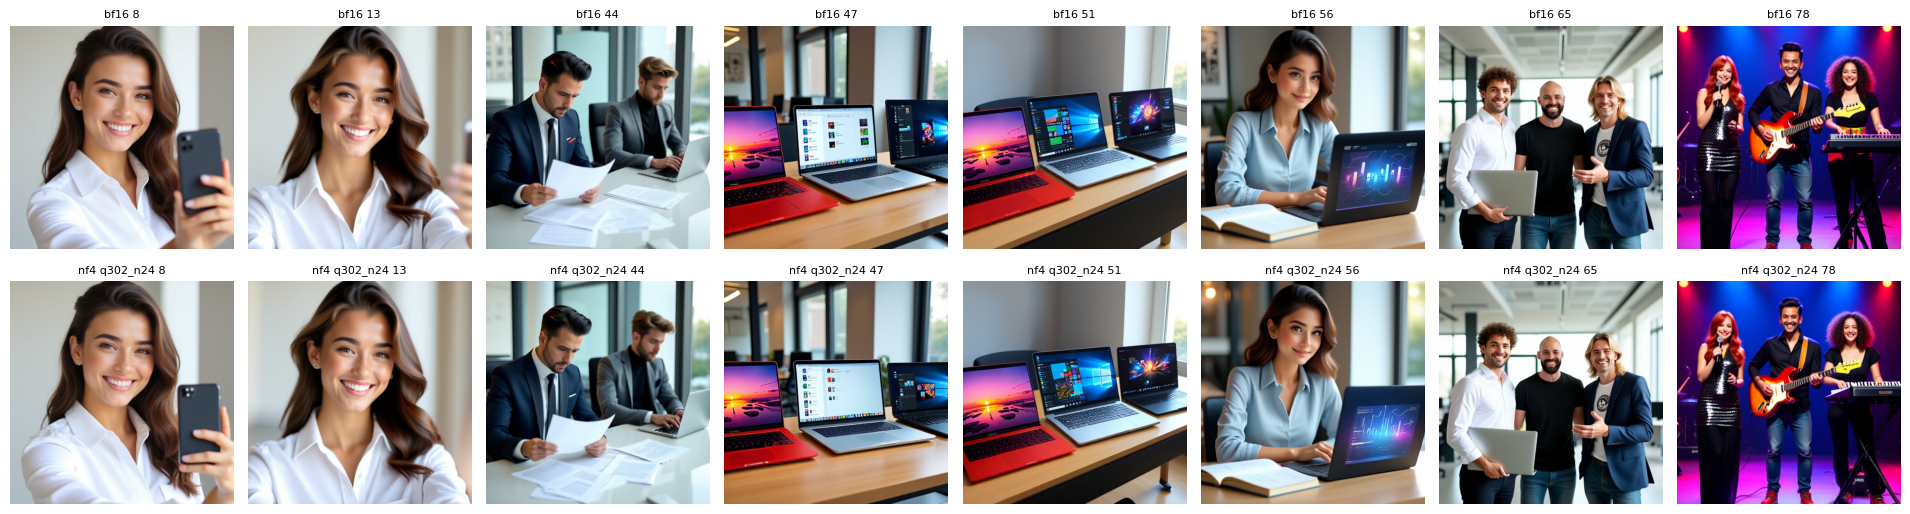

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
BF16 = f"{DATA}/gen/test/baseline"
if not os.path.isdir(BF16): BF16 = f"{DATA}/gen/baseline"
assert os.path.isdir(BF16), f"bf16 baseline images not found under {DATA}/gen"
print("bf16 baseline:", BF16)
n = min(8, len(pick))
fig, ax = plt.subplots(2, n, figsize=(2.4*n, 5.4))
for c, i in enumerate(pick[:n]):
    for r_, src_ in enumerate([BF16, GEN]):
        f = f"{src_}/test_{i:05d}.png" if src_ == BF16 else f"{src_}/{i:05d}.png"
        ax[r_, c].axis("off")
        if os.path.exists(f): ax[r_, c].imshow(Image.open(f))
        ax[r_, c].set_title(("bf16" if r_ == 0 else f"nf4 {TAG}") + f" {i}", fontsize=8)
plt.tight_layout(); plt.show()

## 8. Scored sanity (optional)
Turns the eyeball check into a paired number. Scores the sanity rows with the same GPT-4.1 judge and pairs them against the existing bf16 baseline scores. At n=24 the standard error on a paired Overall delta is about 1.3/sqrt(24) = 0.27, giving an approximate 80%-power MDE of about 0.75 Overall; smaller effects are tested with lower power. Off by default.

In [ ]:
SCORE_SANITY = False
if SCORE_SANITY:
    print(f"scored separately by score_runs_qlora_{TAG.split('_')[0]}: "
          f"DATASET='test', RUN='qlora_nf4_{TAG}', BASE_RUN='baseline'")
else:
    print("SCORE_SANITY=False - skipped")

SCORE_SANITY=False - skipped


## 9. Revert

In [ ]:
subprocess.run(["git","-C",REPO,"checkout","--","train.py"], check=True)
s = open(f"{REPO}/train.py", encoding="utf-8").read()
assert "[qlora]" not in s, "qlora patch not removed"
assert "loss * accelerator.gradient_state.num_steps" in s, "loss normalisation not restored"
print("train.py reverted to HEAD")

train.py reverted to HEAD
